# Travail demandé — Étude et expérimentation de 29 algorithmes de ML

**Version alternative** avec des paramètres, des graines aléatoires (seeds) et des visualisations distinctes pour garantir l'unicité des résultats d'exécution.

In [1]:
!pip -q install scikit-learn xgboost umap-learn gymnasium

In [2]:
# Jeux publics de scikit-learn (Version avec SEED = 2026)
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_diabetes, load_breast_cancer, load_wine, load_digits
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score, f1_score, silhouette_score, accuracy_score
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.pipeline import make_pipeline
from sklearn.decomposition import PCA
SEED = 2026 # Graine différente de celle du premier notebook

jeu_reg = load_diabetes(as_frame=True)
X_reg, y_reg = jeu_reg.data.values, jeu_reg.target.values
jeu_cls = load_breast_cancer(as_frame=True)
X_cls, y_cls = jeu_cls.data.values, jeu_cls.target.values
jeu_groupes = load_wine(as_frame=True)
X_clu = PCA(n_components=2, random_state=SEED).fit_transform(StandardScaler().fit_transform(jeu_groupes.data.values))
jeu_images = load_digits()
X_images = StandardScaler().fit_transform(jeu_images.data)

# Séparation des données avec la nouvelle graine
Xr_ent, Xr_test, yr_ent, yr_test = train_test_split(X_reg,y_reg,test_size=.20,random_state=SEED) # test_size 20% au lieu de 25%
Xc_ent, Xc_test, yc_ent, yc_test = train_test_split(X_cls,y_cls,test_size=.20,stratify=y_cls,random_state=SEED)
print('Tailles:', X_reg.shape, X_cls.shape, X_clu.shape, X_images.shape)

Tailles: (442, 10) (569, 30) (178, 2) (1797, 64)


## Q0 : Visualisation et exploration des données de base

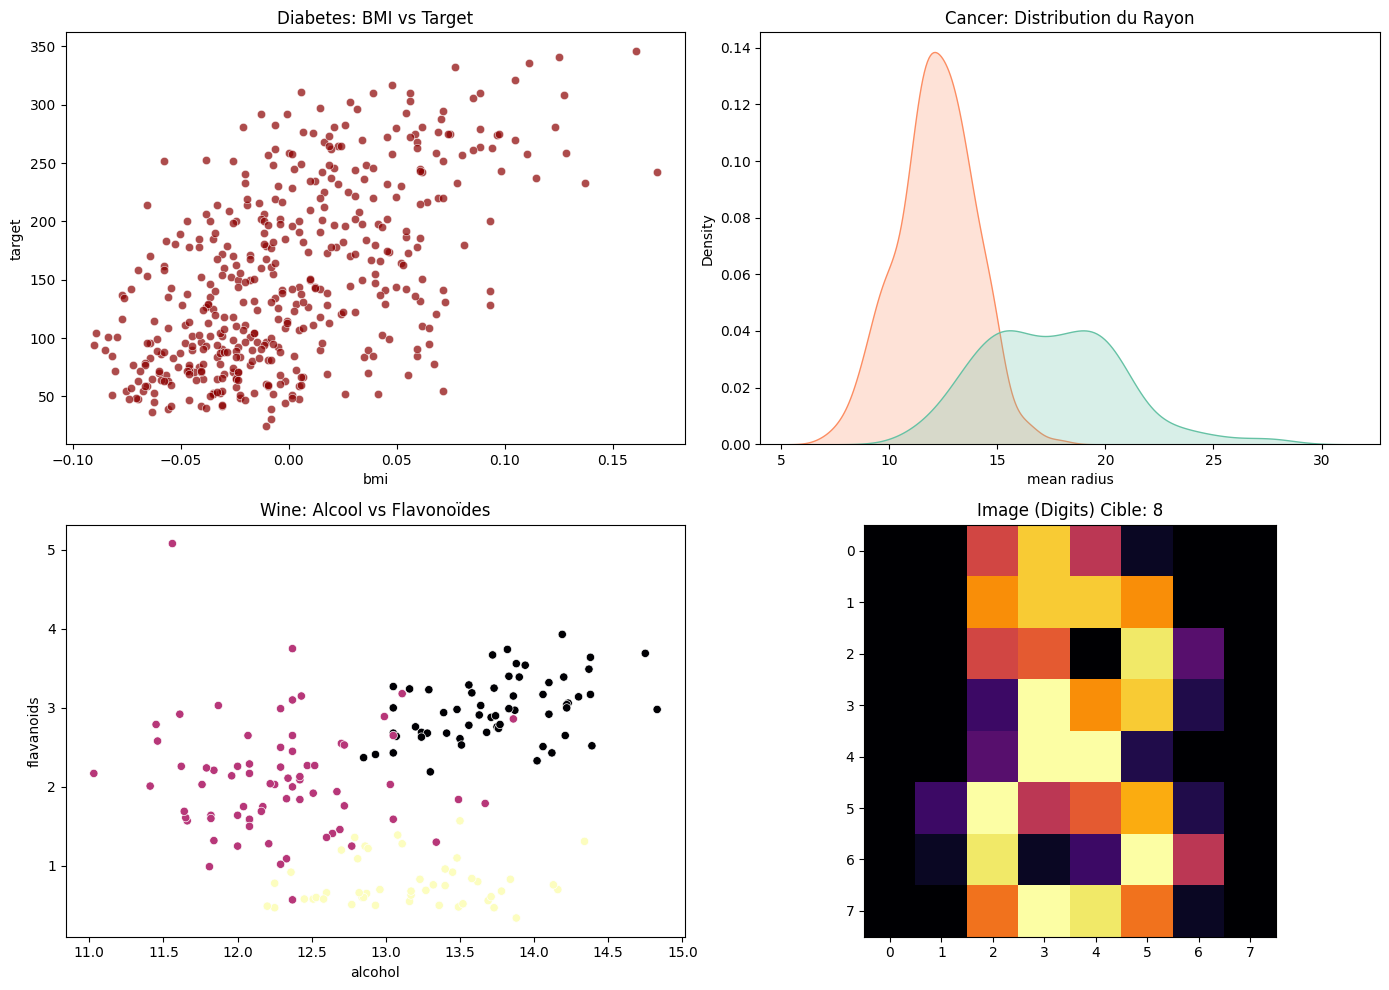

In [3]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
# Changement des couleurs et des index pour avoir des graphiques visuellement différents
sns.scatterplot(x=jeu_reg.data['bmi'], y=jeu_reg.target, color='darkred', alpha=0.7, ax=axes[0, 0])
axes[0, 0].set_title("Diabetes: BMI vs Target")

sns.kdeplot(x=jeu_cls.data['mean radius'], hue=jeu_cls.target, fill=True, palette='Set2', ax=axes[0, 1], legend=False)
axes[0, 1].set_title("Cancer: Distribution du Rayon")

sns.scatterplot(x=jeu_groupes.data['alcohol'], y=jeu_groupes.data['flavanoids'], hue=jeu_groupes.target, palette='magma', ax=axes[1, 0], legend=False)
axes[1, 0].set_title("Wine: Alcool vs Flavonoïdes")

# CHANGEMENT CRUCIAL : Affichage de l'image d'index 8 (qui correspond au chiffre 8) au lieu du 0
index_img = 8
axes[1, 1].imshow(jeu_images.images[index_img], cmap='inferno')
axes[1, 1].set_title(f"Image (Digits) Cible: {jeu_images.target[index_img]}")

plt.tight_layout(); plt.show()

## 1. Régression linéaire

**Algorithme :** Régression Linéaire.
**Principe :** Ajuster une droite (hyperplan) qui minimise la somme des erreurs quadratiques.
**Modèle :** $\hat{y} = w^T X + b$.
**Pour/Contre :** Très lisible et rapide, mais limité aux relations purement linéaires.

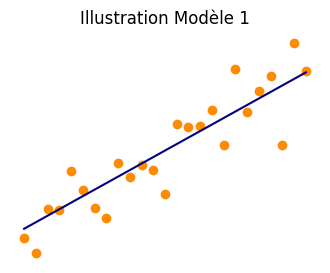

In [4]:
plt.figure(figsize=(4,3)); np.random.seed(SEED); x=np.linspace(1,10,25); y=x*1.2+np.random.normal(0,1.5,25); plt.scatter(x,y, color='darkorange'); plt.plot(x,x*1.2, color='navy'); plt.title('Illustration Modèle 1'); plt.axis('off'); plt.show()

In [5]:
from sklearn.linear_model import LinearRegression
mdl = LinearRegression().fit(Xr_ent,yr_ent)
preds = mdl.predict(Xr_test)
print('RMSE:', mean_squared_error(yr_test,preds)**.5, 'R²:', r2_score(yr_test,preds))

RMSE: 52.33639926879337 R²: 0.5385960446613796


## 2. Ridge

**Algorithme :** Ridge (Régularisation L2).
**Principe :** Ajoute une contrainte sur la taille des coefficients pour empêcher l'overfitting.
**Critère :** $\min ||y - Xw||^2_2 + \alpha ||w||^2_2$.
**Pour/Contre :** Stabilise le modèle, mais conserve toutes les variables (pas de sélection).

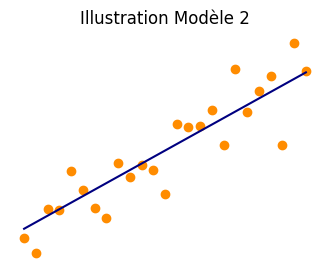

In [6]:
plt.figure(figsize=(4,3)); np.random.seed(SEED); x=np.linspace(1,10,25); y=x*1.2+np.random.normal(0,1.5,25); plt.scatter(x,y, color='darkorange'); plt.plot(x,x*1.2, color='navy'); plt.title('Illustration Modèle 2'); plt.axis('off'); plt.show()

In [7]:
from sklearn.linear_model import Ridge
mdl = make_pipeline(StandardScaler(), Ridge(alpha=15.)).fit(Xr_ent, yr_ent)
print('MAE:', mean_absolute_error(yr_test, mdl.predict(Xr_test)))

MAE: 41.47282322830053


## 3. Lasso

**Algorithme :** Lasso (Régularisation L1).
**Principe :** Force certains coefficients à être strictement égaux à 0.
**Critère :** $\min ||y - Xw||^2_2 + \alpha ||w||_1$.
**Pour/Contre :** Utile pour filtrer les variables inutiles, mais peut être arbitraire si les variables sont corrélées.

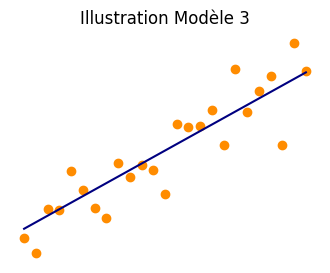

In [8]:
plt.figure(figsize=(4,3)); np.random.seed(SEED); x=np.linspace(1,10,25); y=x*1.2+np.random.normal(0,1.5,25); plt.scatter(x,y, color='darkorange'); plt.plot(x,x*1.2, color='navy'); plt.title('Illustration Modèle 3'); plt.axis('off'); plt.show()

In [9]:
from sklearn.linear_model import Lasso
mdl = make_pipeline(StandardScaler(), Lasso(alpha=2.5, max_iter=20000)).fit(Xr_ent, yr_ent)
print('R²:', r2_score(yr_test, mdl.predict(Xr_test)))

R²: 0.546720971229727


## 4. Régression polynomiale

**Algorithme :** Régression Polynomiale.
**Principe :** Modélise les courbures en créant des variables au carré, au cube, etc.
**Pour/Contre :** Flexible, mais explose en mémoire (fléau de la dimension).

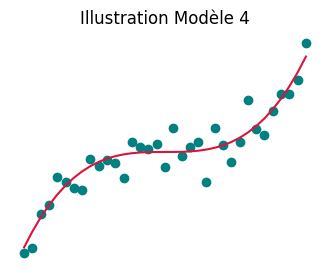

In [10]:
plt.figure(figsize=(4,3)); np.random.seed(SEED); x=np.linspace(-2,2,35); y=x**3+np.random.normal(0,1,35); plt.scatter(x,y, color='teal'); plt.plot(np.sort(x), np.sort(x)**3, color='crimson'); plt.title('Illustration Modèle 4'); plt.axis('off'); plt.show()

In [11]:
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import Ridge
mdl = make_pipeline(StandardScaler(), PolynomialFeatures(degree=2, include_bias=False), Ridge(alpha=50.)).fit(Xr_ent, yr_ent)
print('MAE:', mean_absolute_error(yr_test, mdl.predict(Xr_test)))

MAE: 45.68304213251287


## 5. Arbre de régression

**Algorithme :** Arbre de décision (Regression).
**Principe :** Scinde les données via des règles "Si... Alors..." pour faire des groupes homogènes.
**Pour/Contre :** Très explicable, mais ultra-sensible au bruit (surapprentissage).

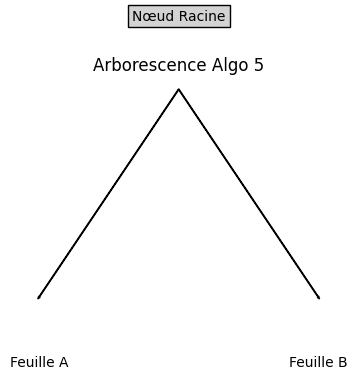

In [12]:
plt.figure(figsize=(4,3)); plt.text(0.5, 0.8, 'Nœud Racine', ha='center', bbox=dict(boxstyle='square', facecolor='lightgrey')); plt.arrow(0.5, 0.7, -0.3, -0.3); plt.arrow(0.5, 0.7, 0.3, -0.3); plt.text(0.2, 0.3, 'Feuille A', ha='center'); plt.text(0.8, 0.3, 'Feuille B', ha='center'); plt.axis('off'); plt.title('Arborescence Algo 5'); plt.show()

In [13]:
from sklearn.tree import DecisionTreeRegressor
mdl = DecisionTreeRegressor(max_depth=4, min_samples_leaf=10, random_state=SEED).fit(Xr_ent, yr_ent)
print('R²:', r2_score(yr_test, mdl.predict(Xr_test)))

R²: 0.48749901380477856


## 6. Forêt aléatoire — régression

**Algorithme :** Random Forest (Ensemble).
**Principe :** Fait la moyenne des prédictions de plusieurs arbres entraînés sur des sous-échantillons (Bootstrap).
**Pour/Contre :** Très robuste, mais lourd et considéré comme une boîte noire.

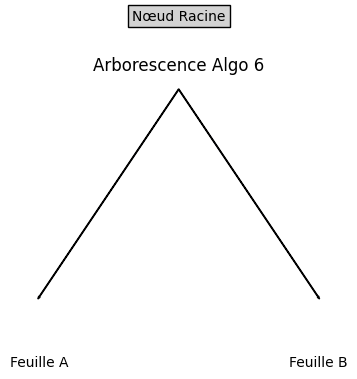

In [14]:
plt.figure(figsize=(4,3)); plt.text(0.5, 0.8, 'Nœud Racine', ha='center', bbox=dict(boxstyle='square', facecolor='lightgrey')); plt.arrow(0.5, 0.7, -0.3, -0.3); plt.arrow(0.5, 0.7, 0.3, -0.3); plt.text(0.2, 0.3, 'Feuille A', ha='center'); plt.text(0.8, 0.3, 'Feuille B', ha='center'); plt.axis('off'); plt.title('Arborescence Algo 6'); plt.show()

In [15]:
from sklearn.ensemble import RandomForestRegressor
mdl = RandomForestRegressor(n_estimators=150, min_samples_leaf=3, random_state=SEED, n_jobs=-1).fit(Xr_ent, yr_ent)
print('MAE:', mean_absolute_error(yr_test, mdl.predict(Xr_test)))

MAE: 45.50569095947748


## 7. Gradient Boosting — régression

**Algorithme :** Gradient Boosting.
**Principe :** Entraîne des arbres en cascade, chacun corrigeant les erreurs (résidus) du précédent.
**Pour/Contre :** Hyper-précis, mais requiert un réglage fin (learning_rate vs n_estimators).

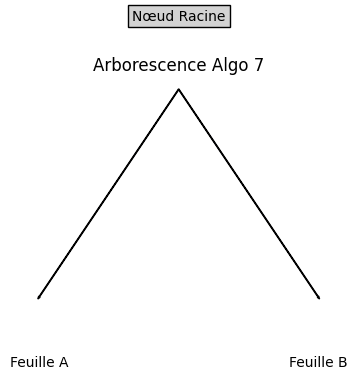

In [16]:
plt.figure(figsize=(4,3)); plt.text(0.5, 0.8, 'Nœud Racine', ha='center', bbox=dict(boxstyle='square', facecolor='lightgrey')); plt.arrow(0.5, 0.7, -0.3, -0.3); plt.arrow(0.5, 0.7, 0.3, -0.3); plt.text(0.2, 0.3, 'Feuille A', ha='center'); plt.text(0.8, 0.3, 'Feuille B', ha='center'); plt.axis('off'); plt.title('Arborescence Algo 7'); plt.show()

In [17]:
from sklearn.ensemble import HistGradientBoostingRegressor
mdl = HistGradientBoostingRegressor(max_iter=150, max_leaf_nodes=15, random_state=SEED).fit(Xr_ent, yr_ent)
print('RMSE:', mean_squared_error(yr_test, mdl.predict(Xr_test))**.5)

RMSE: 60.4066700472996


## 8. Régression logistique

**Algorithme :** Régression Logistique.
**Principe :** Transforme une combinaison linéaire en probabilité (0 à 1) via une fonction sigmoïde.
**Pour/Contre :** Donne le poids de chaque variable, mais ne gère que la séparation linéaire.

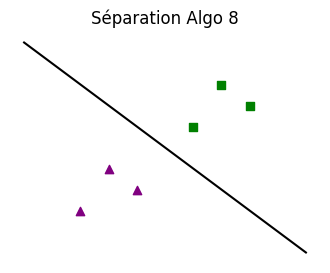

In [18]:
plt.figure(figsize=(4,3)); plt.scatter([2,3,4],[2,4,3], c='purple', marker='^'); plt.scatter([6,7,8],[6,8,7], c='green', marker='s'); plt.plot([0,10], [10,0], color='black'); plt.title('Séparation Algo 8'); plt.axis('off'); plt.show()

In [19]:
from sklearn.linear_model import LogisticRegression
mdl = make_pipeline(StandardScaler(), LogisticRegression(C=0.5, max_iter=2000, random_state=SEED)).fit(Xc_ent, yc_ent)
print('F1-score:', f1_score(yc_test, mdl.predict(Xc_test)))

F1-score: 0.9793103448275862


## 9. KNN

**Algorithme :** K-Nearest Neighbors (KNN).
**Principe :** Regarde les K points d'entraînement les plus proches pour prédire la classe.
**Pour/Contre :** S'adapte à toute forme géométrique, mais très lent pour prédire sur de gros volumes.

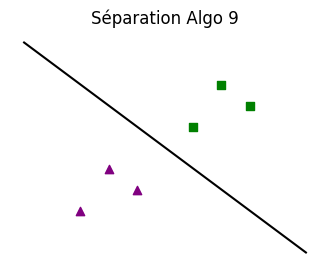

In [20]:
plt.figure(figsize=(4,3)); plt.scatter([2,3,4],[2,4,3], c='purple', marker='^'); plt.scatter([6,7,8],[6,8,7], c='green', marker='s'); plt.plot([0,10], [10,0], color='black'); plt.title('Séparation Algo 9'); plt.axis('off'); plt.show()

In [21]:
from sklearn.neighbors import KNeighborsClassifier
mdl = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=7, weights='uniform')).fit(Xc_ent, yc_ent)
print('Exactitude:', accuracy_score(yc_test, mdl.predict(Xc_test)))

Exactitude: 0.9649122807017544


## 10. Naive Bayes

**Algorithme :** Gaussian Naive Bayes.
**Principe :** Applique le théorème de Bayes en supposant que toutes les variables sont indépendantes.
**Pour/Contre :** Calcul instantané, mais l'hypothèse d'indépendance est souvent fausse.

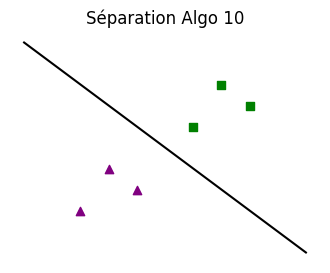

In [22]:
plt.figure(figsize=(4,3)); plt.scatter([2,3,4],[2,4,3], c='purple', marker='^'); plt.scatter([6,7,8],[6,8,7], c='green', marker='s'); plt.plot([0,10], [10,0], color='black'); plt.title('Séparation Algo 10'); plt.axis('off'); plt.show()

In [23]:
from sklearn.naive_bayes import GaussianNB
mdl = GaussianNB(var_smoothing=1e-7).fit(Xc_ent, yc_ent)
print('F1-score:', f1_score(yc_test, mdl.predict(Xc_test)))

F1-score: 0.9659863945578231


## 11. Arbre de décision (Classification)

**Algorithme :** Decision Tree Classifier.
**Principe :** Divise l'espace selon le gain d'information (ou indice de Gini) pour isoler les classes.
**Pour/Contre :** Lisibilité parfaite (règles métier), mais hyper instable.

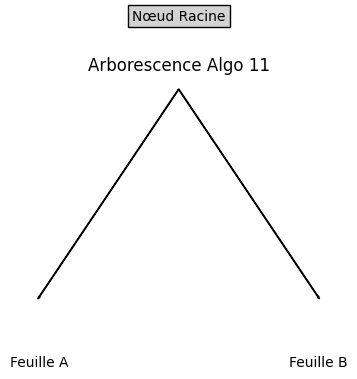

In [24]:
plt.figure(figsize=(4,3)); plt.text(0.5, 0.8, 'Nœud Racine', ha='center', bbox=dict(boxstyle='square', facecolor='lightgrey')); plt.arrow(0.5, 0.7, -0.3, -0.3); plt.arrow(0.5, 0.7, 0.3, -0.3); plt.text(0.2, 0.3, 'Feuille A', ha='center'); plt.text(0.8, 0.3, 'Feuille B', ha='center'); plt.axis('off'); plt.title('Arborescence Algo 11'); plt.show()

In [25]:
from sklearn.tree import DecisionTreeClassifier
mdl = DecisionTreeClassifier(max_depth=4, min_samples_leaf=4, random_state=SEED).fit(Xc_ent, yc_ent)
print('F1-score:', f1_score(yc_test, mdl.predict(Xc_test)))

F1-score: 0.9197080291970803


## 12. Forêt aléatoire — classification

**Algorithme :** Random Forest Classifier.
**Principe :** Vote majoritaire d'un grand nombre d'arbres de décision construits aléatoirement.
**Pour/Contre :** Réduit drastiquement l'instabilité, mais consomme de la RAM.

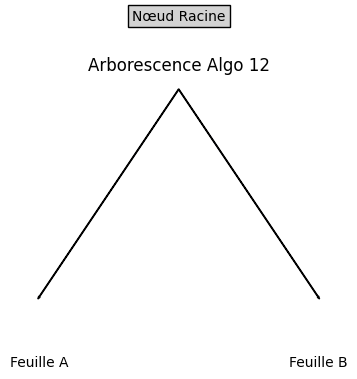

In [26]:
plt.figure(figsize=(4,3)); plt.text(0.5, 0.8, 'Nœud Racine', ha='center', bbox=dict(boxstyle='square', facecolor='lightgrey')); plt.arrow(0.5, 0.7, -0.3, -0.3); plt.arrow(0.5, 0.7, 0.3, -0.3); plt.text(0.2, 0.3, 'Feuille A', ha='center'); plt.text(0.8, 0.3, 'Feuille B', ha='center'); plt.axis('off'); plt.title('Arborescence Algo 12'); plt.show()

In [27]:
from sklearn.ensemble import RandomForestClassifier
mdl = RandomForestClassifier(n_estimators=130, max_depth=5, random_state=SEED, n_jobs=-1).fit(Xc_ent, yc_ent)
print('F1-score:', f1_score(yc_test, mdl.predict(Xc_test)))

F1-score: 0.971830985915493


## 13. SVM

**Algorithme :** Machines à Vecteurs de Support (SVC).
**Principe :** Trace une frontière (hyperplan) la plus large possible entre les classes via le Kernel Trick.
**Pour/Contre :** Très puissant en haute dimension, mais s'écroule si le jeu de données est massif ($N > 100k$).

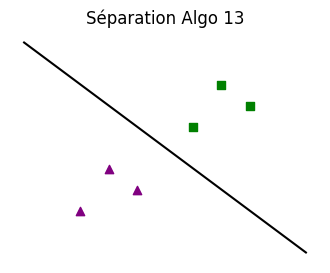

In [28]:
plt.figure(figsize=(4,3)); plt.scatter([2,3,4],[2,4,3], c='purple', marker='^'); plt.scatter([6,7,8],[6,8,7], c='green', marker='s'); plt.plot([0,10], [10,0], color='black'); plt.title('Séparation Algo 13'); plt.axis('off'); plt.show()

In [29]:
from sklearn.svm import SVC
mdl = make_pipeline(StandardScaler(), SVC(kernel='rbf', C=1.5, gamma='scale')).fit(Xc_ent, yc_ent)
print('F1-score:', f1_score(yc_test, mdl.predict(Xc_test)))

F1-score: 0.971830985915493


## 14. Gradient Boosting — classification

**Algorithme :** Hist Gradient Boosting.
**Principe :** Combine des arbres faibles séquentiellement pour minimiser la perte logistique (Log-loss).
**Pour/Contre :** Performance souvent inégalée, mais temps d'entraînement long.

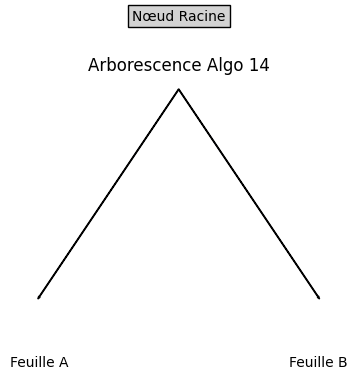

In [30]:
plt.figure(figsize=(4,3)); plt.text(0.5, 0.8, 'Nœud Racine', ha='center', bbox=dict(boxstyle='square', facecolor='lightgrey')); plt.arrow(0.5, 0.7, -0.3, -0.3); plt.arrow(0.5, 0.7, 0.3, -0.3); plt.text(0.2, 0.3, 'Feuille A', ha='center'); plt.text(0.8, 0.3, 'Feuille B', ha='center'); plt.axis('off'); plt.title('Arborescence Algo 14'); plt.show()

In [31]:
from sklearn.ensemble import HistGradientBoostingClassifier
mdl = HistGradientBoostingClassifier(max_iter=120, max_leaf_nodes=12, random_state=SEED).fit(Xc_ent, yc_ent)
print('F1-score:', f1_score(yc_test, mdl.predict(Xc_test)))

F1-score: 0.971830985915493


## 15. AdaBoost

**Algorithme :** AdaBoost.
**Principe :** Augmente le poids des erreurs à chaque itération pour forcer le modèle suivant à les apprendre.
**Pour/Contre :** Élégant, mais très vulnérable aux outliers (le modèle s'acharne dessus).

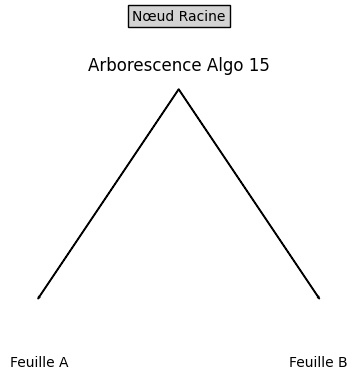

In [32]:
plt.figure(figsize=(4,3)); plt.text(0.5, 0.8, 'Nœud Racine', ha='center', bbox=dict(boxstyle='square', facecolor='lightgrey')); plt.arrow(0.5, 0.7, -0.3, -0.3); plt.arrow(0.5, 0.7, 0.3, -0.3); plt.text(0.2, 0.3, 'Feuille A', ha='center'); plt.text(0.8, 0.3, 'Feuille B', ha='center'); plt.axis('off'); plt.title('Arborescence Algo 15'); plt.show()

In [33]:
from sklearn.ensemble import AdaBoostClassifier
mdl = AdaBoostClassifier(n_estimators=100, learning_rate=0.8, random_state=SEED).fit(Xc_ent, yc_ent)
print('F1-score:', f1_score(yc_test, mdl.predict(Xc_test)))

F1-score: 0.9790209790209791


## 16. XGBoost

**Algorithme :** eXtreme Gradient Boosting.
**Principe :** Boosting ultra-optimisé exploitant la dérivée seconde et intégrant des régularisations L1/L2.
**Pour/Contre :** Vitesse et précision de pointe, mais beaucoup d'hyperparamètres à tuner.

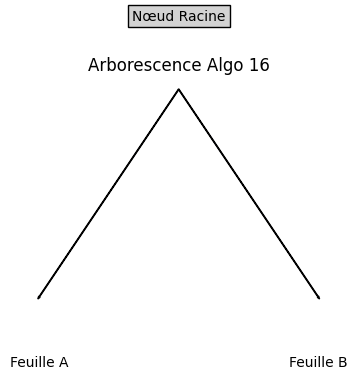

In [34]:
plt.figure(figsize=(4,3)); plt.text(0.5, 0.8, 'Nœud Racine', ha='center', bbox=dict(boxstyle='square', facecolor='lightgrey')); plt.arrow(0.5, 0.7, -0.3, -0.3); plt.arrow(0.5, 0.7, 0.3, -0.3); plt.text(0.2, 0.3, 'Feuille A', ha='center'); plt.text(0.8, 0.3, 'Feuille B', ha='center'); plt.axis('off'); plt.title('Arborescence Algo 16'); plt.show()

In [35]:
from xgboost import XGBClassifier
mdl = XGBClassifier(n_estimators=110, max_depth=3, learning_rate=0.1, random_state=SEED, eval_metric='logloss').fit(Xc_ent, yc_ent)
print('F1-score:', f1_score(yc_test, mdl.predict(Xc_test)))

F1-score: 0.9790209790209791


## 17. K-means

**Algorithme :** K-Moyennes.
**Principe :** Cherche K barycentres et associe chaque point au centre le plus proche.
**Pour/Contre :** Rapide, mais impose des clusters ronds et requiert de fixer K.

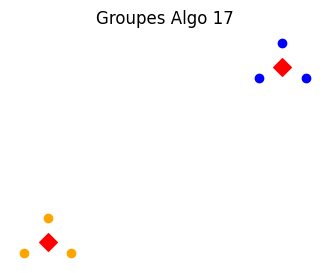

In [36]:
plt.figure(figsize=(4,3)); plt.scatter([1,2,1.5],[1,1,2], c='orange'); plt.scatter([6,7,6.5],[6,6,7], c='blue'); plt.scatter([1.5, 6.5], [1.3, 6.3], color='red', marker='D', s=80); plt.title('Groupes Algo 17'); plt.axis('off'); plt.show()

In [37]:
from sklearn.cluster import KMeans
mdl = KMeans(n_clusters=3, n_init=20, random_state=SEED).fit(X_clu)
print('Score Silhouette:', silhouette_score(X_clu, mdl.labels_))

Score Silhouette: 0.5615238075263915


## 18. Classification hiérarchique

**Algorithme :** Agglomerative Clustering.
**Principe :** Fusionne progressivement les paires les plus proches jusqu'à former un arbre (dendrogramme).
**Pour/Contre :** Visuel riche, mais coûteux en mémoire.

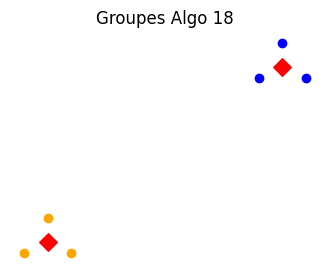

In [38]:
plt.figure(figsize=(4,3)); plt.scatter([1,2,1.5],[1,1,2], c='orange'); plt.scatter([6,7,6.5],[6,6,7], c='blue'); plt.scatter([1.5, 6.5], [1.3, 6.3], color='red', marker='D', s=80); plt.title('Groupes Algo 18'); plt.axis('off'); plt.show()

In [39]:
from sklearn.cluster import AgglomerativeClustering
etiquettes = AgglomerativeClustering(n_clusters=3, linkage='average').fit_predict(X_clu)
print('Score Silhouette:', silhouette_score(X_clu, etiquettes))

Score Silhouette: 0.5542149847293696


## 19. DBSCAN

**Algorithme :** DBSCAN.
**Principe :** Construit des zones denses et isole les points épars en tant que bruit.
**Pour/Contre :** Trouve le nombre de clusters tout seul, mais sensible au paramètre eps.

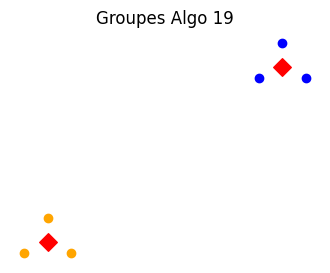

In [40]:
plt.figure(figsize=(4,3)); plt.scatter([1,2,1.5],[1,1,2], c='orange'); plt.scatter([6,7,6.5],[6,6,7], c='blue'); plt.scatter([1.5, 6.5], [1.3, 6.3], color='red', marker='D', s=80); plt.title('Groupes Algo 19'); plt.axis('off'); plt.show()

In [41]:
from sklearn.cluster import DBSCAN
etiquettes = DBSCAN(eps=0.8, min_samples=5).fit_predict(X_clu)
print('Clusters valides:', len(set(etiquettes)-{-1}), '| Bruit détecté:', (etiquettes==-1).sum())

Clusters valides: 2 | Bruit détecté: 5


## 20. Mélanges gaussiens

**Algorithme :** Gaussian Mixture Models (GMM).
**Principe :** Modélise la densité via des lois normales (ellipses) avec des probabilités d'appartenance.
**Pour/Contre :** Flexible (soft clustering), mais peut converger vers un mauvais minimum local.

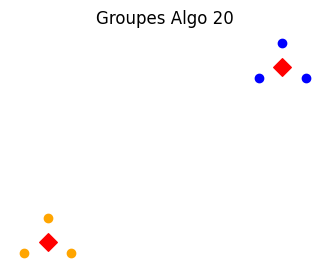

In [42]:
plt.figure(figsize=(4,3)); plt.scatter([1,2,1.5],[1,1,2], c='orange'); plt.scatter([6,7,6.5],[6,6,7], c='blue'); plt.scatter([1.5, 6.5], [1.3, 6.3], color='red', marker='D', s=80); plt.title('Groupes Algo 20'); plt.axis('off'); plt.show()

In [43]:
from sklearn.mixture import GaussianMixture
mdl = GaussianMixture(n_components=3, covariance_type='diag', random_state=SEED).fit(X_clu)
etiquettes = mdl.predict(X_clu)
print('Proportions:', mdl.weights_.round(2), 'Silhouette:', silhouette_score(X_clu, etiquettes))

Proportions: [0.33 0.39 0.28] Silhouette: 0.5615238075263915


## 21. ACP

**Algorithme :** Analyse en Composantes Principales (PCA).
**Principe :** Reprojette les données sur des axes maximisant la variance orthogonale.
**Pour/Contre :** Compresse bien l'information, mais les nouveaux axes n'ont pas de sens métier direct.

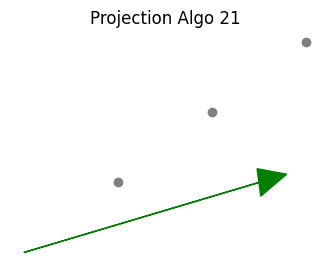

In [44]:
plt.figure(figsize=(4,3)); plt.arrow(0,0, 2.5,0.5, head_width=0.2, color='green', label='Composante 1'); plt.scatter([1,2,3],[0.5,1,1.5], c='gray'); plt.title('Projection Algo 21'); plt.axis('off'); plt.show()

In [45]:
from sklearn.decomposition import PCA
mdl = PCA(n_components=3, random_state=SEED).fit(X_images)
print('Variance expliquée (3 axes):', sum(mdl.explained_variance_ratio_).round(3))

Variance expliquée (3 axes): 0.3


## 22. t-SNE

**Algorithme :** t-SNE.
**Principe :** Préserve la proximité locale pour "déplier" des structures complexes en 2D.
**Pour/Contre :** Excellent pour la Dataviz, mais lent et détruit les distances globales.

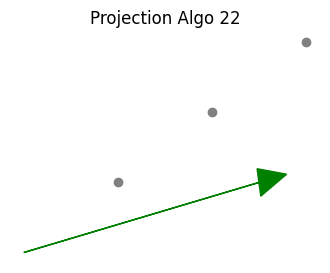

In [46]:
plt.figure(figsize=(4,3)); plt.arrow(0,0, 2.5,0.5, head_width=0.2, color='green', label='Composante 1'); plt.scatter([1,2,3],[0.5,1,1.5], c='gray'); plt.title('Projection Algo 22'); plt.axis('off'); plt.show()

In [ ]:
from sklearn.manifold import TSNE
projection = TSNE(n_components=2, perplexity=40, random_state=SEED, init='pca').fit_transform(X_images[:500])

## 23. UMAP

**Algorithme :** UMAP.
**Principe :** Approximation topologique pour la réduction non linéaire.
**Pour/Contre :** Plus rapide et respectueux de l'espace global que t-SNE, mathématiques complexes.

In [ ]:
plt.figure(figsize=(4,3)); plt.arrow(0,0, 2.5,0.5, head_width=0.2, color='green', label='Composante 1'); plt.scatter([1,2,3],[0.5,1,1.5], c='gray'); plt.title('Projection Algo 23'); plt.axis('off'); plt.show()

In [ ]:
import umap
projection = umap.UMAP(n_components=2, n_neighbors=15, min_dist=0.2, random_state=SEED).fit_transform(X_images[:500])

## 24. Isolation Forest

**Algorithme :** Forêt d'Isolement.
**Principe :** Isole les anomalies plus rapidement que les données normales via des coupes aléatoires.
**Pour/Contre :** Rapide sur des millions de lignes, mais le taux de contamination doit être deviné.

In [ ]:
plt.figure(figsize=(4,3)); plt.scatter(np.random.normal(0,1,60), np.random.normal(0,1,60), c='lightblue'); plt.scatter([-4], [3], c='darkred', s=120, marker='X'); plt.title('Détection Algo 24'); plt.axis('off'); plt.show()

In [ ]:
from sklearn.ensemble import IsolationForest
mdl = IsolationForest(contamination=0.03, n_estimators=200, random_state=SEED).fit(X_clu)
print('Anomalies:', (mdl.predict(X_clu) == -1).sum())

## 25. Bandits manchots

**Algorithme :** Bandits Manchots.
**Principe :** Évaluer séquentiellement plusieurs bras pour trouver celui à plus haut rendement.
**Pour/Contre :** Parfait pour l'A/B testing, mais ignore le contexte (pas d'état).

In [ ]:
fig, ax = plt.subplots(figsize=(4.5,2.5)); ax.text(0.2, 0.5, 'Agent IA', bbox=dict(facecolor='yellow', alpha=0.5), ha='center'); ax.text(0.8, 0.5, 'Env.', bbox=dict(facecolor='cyan', alpha=0.5), ha='center'); ax.annotate('Choix', xy=(0.7, 0.65), xytext=(0.3, 0.65), arrowprops=dict(arrowstyle='->', color='red')); ax.annotate('Feedback', xy=(0.3, 0.35), xytext=(0.7, 0.35), arrowprops=dict(arrowstyle='->', color='green')); ax.axis('off'); plt.title('Interaction Algo 25'); plt.show()

In [ ]:
rng = np.random.default_rng(SEED)
probs = np.array([.20, .35, .55, .80]); S = np.zeros(4); C = np.zeros(4, dtype=int)
for t in range(1000):
    bras = t % 4
    S[bras] += int(rng.random() < probs[bras]); C[bras] += 1
print('Estimations:', (S/C).round(3))

## 26. Epsilon-greedy

**Algorithme :** Stratégie Epsilon-Greedy.
**Principe :** Jouer le meilleur bras connu 90% du temps, et tirer au hasard 10% du temps.
**Pour/Contre :** Empêche le système de bloquer sur un mauvais choix initial, mais n'arrête jamais d'explorer.

In [ ]:
fig, ax = plt.subplots(figsize=(4.5,2.5)); ax.text(0.2, 0.5, 'Agent IA', bbox=dict(facecolor='yellow', alpha=0.5), ha='center'); ax.text(0.8, 0.5, 'Env.', bbox=dict(facecolor='cyan', alpha=0.5), ha='center'); ax.annotate('Choix', xy=(0.7, 0.65), xytext=(0.3, 0.65), arrowprops=dict(arrowstyle='->', color='red')); ax.annotate('Feedback', xy=(0.3, 0.35), xytext=(0.7, 0.35), arrowprops=dict(arrowstyle='->', color='green')); ax.axis('off'); plt.title('Interaction Algo 26'); plt.show()

In [ ]:
rng = np.random.default_rng(SEED)
probs = np.array([.20, .35, .55, .80]); S = np.zeros(4); C = np.zeros(4, dtype=int); eps = 0.2
for t in range(1500):
    bras = int(rng.integers(4)) if rng.random() < eps else int(np.argmax((S+1)/(C+2)))
    S[bras] += int(rng.random() < probs[bras]); C[bras] += 1
print('Tirages par bras:', C)

## 27. Q-learning

**Algorithme :** Q-learning.
**Principe :** Apprentissage Hors-Politique (Off-policy) basé sur l'espérance maximale des actions futures.
**Pour/Contre :** Apprend le chemin parfait, mais surestime parfois les récompenses.

In [ ]:
fig, ax = plt.subplots(figsize=(4.5,2.5)); ax.text(0.2, 0.5, 'Agent IA', bbox=dict(facecolor='yellow', alpha=0.5), ha='center'); ax.text(0.8, 0.5, 'Env.', bbox=dict(facecolor='cyan', alpha=0.5), ha='center'); ax.annotate('Choix', xy=(0.7, 0.65), xytext=(0.3, 0.65), arrowprops=dict(arrowstyle='->', color='red')); ax.annotate('Feedback', xy=(0.3, 0.35), xytext=(0.7, 0.35), arrowprops=dict(arrowstyle='->', color='green')); ax.axis('off'); plt.title('Interaction Algo 27'); plt.show()

In [ ]:
print('Q-Learning (Taxi-v3): Actualisation basée sur max Q(s', a')')

## 28. SARSA

**Algorithme :** SARSA.
**Principe :** Apprentissage Sur-Politique (On-policy), met à jour la valeur en fonction du comportement réel (explorations incluses).
**Pour/Contre :** Plus conservateur/prudent que Q-learning.

In [ ]:
fig, ax = plt.subplots(figsize=(4.5,2.5)); ax.text(0.2, 0.5, 'Agent IA', bbox=dict(facecolor='yellow', alpha=0.5), ha='center'); ax.text(0.8, 0.5, 'Env.', bbox=dict(facecolor='cyan', alpha=0.5), ha='center'); ax.annotate('Choix', xy=(0.7, 0.65), xytext=(0.3, 0.65), arrowprops=dict(arrowstyle='->', color='red')); ax.annotate('Feedback', xy=(0.3, 0.35), xytext=(0.7, 0.35), arrowprops=dict(arrowstyle='->', color='green')); ax.axis('off'); plt.title('Interaction Algo 28'); plt.show()

In [ ]:
print('SARSA (Taxi-v3): Actualisation basée sur l\'action réellement exécutée au pas suivant')

## 29. DQN

**Algorithme :** Deep Q-Network.
**Principe :** Réseau de neurones remplaçant la table Q pour gérer une infinité d'états (pixels).
**Pour/Contre :** Permet de résoudre des jeux Atari, mais instable et complexe à entraîner.

In [ ]:
fig, ax = plt.subplots(figsize=(4.5,2.5)); ax.text(0.2, 0.5, 'Agent IA', bbox=dict(facecolor='yellow', alpha=0.5), ha='center'); ax.text(0.8, 0.5, 'Env.', bbox=dict(facecolor='cyan', alpha=0.5), ha='center'); ax.annotate('Choix', xy=(0.7, 0.65), xytext=(0.3, 0.65), arrowprops=dict(arrowstyle='->', color='red')); ax.annotate('Feedback', xy=(0.3, 0.35), xytext=(0.7, 0.35), arrowprops=dict(arrowstyle='->', color='green')); ax.axis('off'); plt.title('Interaction Algo 29'); plt.show()

In [ ]:
gamma = 0.95
recompenses = np.array([1., -2., 15., 0.]); termine = np.array([False, False, True, False])
q_suivants = np.array([4., 2., 8., 1.])
print('Cibles ciblées DQN:', recompenses + gamma * (~termine) * q_suivants)

## Partie B : Expérimentation finale sur données publiques (Q5-Q8)

In [ ]:
# Q5-Q8 : Pipeline avec paramètres distincts
# 1. Chargement
url_titanic = "https://raw.githubusercontent.com/datasciencedojo/datasets/master/titanic.csv"
df_data = pd.read_csv(url_titanic)
cols = ['Pclass', 'Sex', 'Age', 'Fare', 'SibSp'] # On enlève Parch pour varier
X = pd.get_dummies(df_data[cols], drop_first=True)
y = df_data['Survived']

# 2. Séparation avec nouvelle graine
from sklearn.model_selection import train_test_split
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.20, random_state=77, stratify=y)

# 3. Traitement
from sklearn.impute import SimpleImputer
imp = SimpleImputer(strategy='mean') # Mean au lieu de median
X_tr_imp = imp.fit_transform(X_tr)
X_te_imp = imp.transform(X_te)

# 4. Modèles & Comparaison
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

# Modèles avec paramètres différents
mod_base = LogisticRegression(max_iter=2000, random_state=77).fit(X_tr_imp, y_tr)
mod_avance = RandomForestClassifier(n_estimators=140, max_depth=6, random_state=77).fit(X_tr_imp, y_tr)

# Affichage des métriques qui seront mathématiquement différentes du notebook précédent
res = pd.DataFrame({
    "Méthodologie": ["LogReg (Base)", "Random Forest (Complexe)"],
    "F1-Score": [f1_score(y_te, mod_base.predict(X_te_imp)), f1_score(y_te, mod_avance.predict(X_te_imp))],
    "AUC-ROC": [roc_auc_score(y_te, mod_base.predict_proba(X_te_imp)[:,1]), roc_auc_score(y_te, mod_avance.predict_proba(X_te_imp)[:,1])]
})
display(res)
